# Klasifikasi Depresi pada Mahasiswa Menggunakan Algoritma Decision Tree (CART): Analisis Aturan Keputusan dengan dan tanpa Variabel Dominan

**Proposal Penelitian Data Mining - Notebook Final (proposal + implementasi)**

| | |
|---|---|
| Nama / Kelompok | *(isi)* |
| NIM | *(isi)* |
| Mata kuliah / Dosen | *(isi)* |
| Algoritma | Decision Tree (CART) - satu algoritma |
| Dataset | Student Depression Dataset (Kaggle, hopesb) - sampel 2.000 data |

**Daftar isi**
1. Identifikasi Masalah dan Tujuan (Soal 1)
2. Studi Literatur dan Kebaruan (Soal 2)
3. Perancangan Dataset dan Atribut (Soal 3) + implementasi
4. Perancangan Metode Data Mining (Soal 4) + implementasi
5. Rancangan Eksperimen dan Evaluasi (Soal 5) + implementasi
6. Rencana Pelaksanaan (Soal 6)
7. Kesimpulan otomatis dan Daftar Pustaka

> **Catatan etika:** hasil model hanyalah pola risiko dari data survei, **bukan alat diagnosis**. Diagnosis tetap wewenang tenaga profesional.

---
# BAGIAN I - PROPOSAL

## 1. Identifikasi Masalah dan Tujuan Penelitian (Soal 1)

### 1.1 Topik dan judul
**Klasifikasi Depresi pada Mahasiswa Menggunakan Algoritma Decision Tree (CART): Analisis Aturan Keputusan dengan dan tanpa Variabel Dominan**

### 1.2 Latar belakang
Depresi merupakan salah satu masalah kesehatan mental yang paling umum, termasuk di kalangan mahasiswa. Masa kuliah menghadirkan banyak tekanan sekaligus: tuntutan akademik, kekhawatiran finansial, perubahan lingkungan sosial, dan pola tidur yang tidak teratur. Jika tidak terdeteksi sejak dini, depresi dapat menurunkan prestasi akademik, mengganggu hubungan sosial, dan pada kasus berat meningkatkan risiko membahayakan diri sendiri.

Deteksi dini sering terhambat oleh stigma dan keterbatasan layanan konseling di kampus. Di sisi lain, perguruan tinggi memiliki banyak data survei mahasiswa yang belum dimanfaatkan optimal. Teknik *data mining* dapat membantu menemukan pola faktor risiko dari data tersebut.

Sejumlah penelitian terdahulu memakai algoritma seperti Random Forest, Naive Bayes, dan KNN untuk memprediksi depresi mahasiswa dan umumnya berfokus pada akurasi. Padahal di bidang kesehatan, model yang hanya akurat belum cukup: pengambil keputusan perlu memahami alasan di balik prediksinya. Decision Tree menjawab kebutuhan ini karena menghasilkan aturan yang transparan dan mudah ditelusuri.

Selain itu, ada risiko bahwa akurasi tinggi berasal dari satu variabel yang terlalu dominan (misalnya pertanyaan tentang pikiran bunuh diri), sehingga model kurang bermanfaat untuk memahami faktor penyebab lain. Penelitian ini mengisi celah tersebut dengan membandingkan kinerja model dengan dan tanpa variabel dominan, serta menyajikan aturan keputusan yang dapat diinterpretasikan.

### 1.3 Urgensi penelitian
- Depresi mahasiswa memerlukan alat bantu skrining awal yang murah dan cepat.
- Model yang dapat dijelaskan (*interpretable*) lebih mudah diterima pengambil keputusan di bidang kesehatan.
- Perlu diketahui apakah faktor akademik, finansial, dan gaya hidup masih informatif ketika variabel dominan dikeluarkan.

### 1.4 Rumusan masalah
1. Seberapa baik algoritma Decision Tree (CART) mengklasifikasikan depresi pada mahasiswa?
2. Bagaimana pengaruh variabel dominan terhadap kinerja model?
3. Faktor dan aturan keputusan apa yang paling menentukan klasifikasi depresi?
4. Apakah penanganan ketidakseimbangan kelas (`class_weight`) meningkatkan kemampuan mendeteksi kelas depresi?

### 1.5 Tujuan penelitian
1. Membangun model klasifikasi depresi mahasiswa dengan Decision Tree (CART).
2. Membandingkan kinerja model dengan dan tanpa variabel dominan.
3. Mengidentifikasi fitur terpenting dan mengekstrak aturan keputusan yang mudah dibaca.
4. Menguji pengaruh `class_weight='balanced'` terhadap recall kelas depresi.

### 1.6 Manfaat
- **Praktis:** gambaran faktor risiko untuk program deteksi dini dan layanan konseling kampus.
- **Akademis:** tambahan kajian model yang dapat dijelaskan pada data kesehatan mental mahasiswa.

## 2. Studi Literatur dan Kebaruan Penelitian (Soal 2)

### 2.1 Penelitian terdahulu yang relevan
| No | Penelitian | Ringkasan relevansi |
|---|---|---|
| 1 | Jurnal CoreIT, UIN Suska (2025) [1] | Prediksi depresi mahasiswa dengan *Particle Swarm Optimization* dan Random Forest pada *Student Depression Dataset* (sekitar 27.900 responden, 18 atribut). |
| 2 | Setiawan, Yasin & Desianti, IKOMTI [2] | Membandingkan Random Forest, Decision Tree, Naive Bayes, dan KNN untuk depresi mahasiswa. |
| 3 | Prosiding 55 JAIIO (2026) [3] | Metodologi KDD pada dataset depresi mahasiswa publik, termasuk penanganan outlier dan penyeimbangan kelas dengan SMOTE. |
| 4 | Jayadi dkk. [4] | Deteksi dini kesehatan mental mahasiswa: perbandingan Decision Tree dan Random Forest; menekankan keunggulan interpretabilitas Decision Tree. |
| 5 | Anggreani, Danuputri dkk. [5] | Klasifikasi kesehatan mental mahasiswa berdasarkan variabel akademik dan sosial dengan Decision Tree. |

> Ringkasan di atas berdasarkan abstrak artikel. **Baca naskah lengkap, lalu lengkapi nama penulis, tahun, dan volume pada Daftar Pustaka.**

### 2.2 Celah penelitian (*research gap*)
Sebagian besar studi membandingkan banyak algoritma dan menonjolkan akurasi, sementara (a) ketergantungan model pada satu variabel dominan dan (b) aturan keputusan yang bisa dibaca manusia belum banyak dikaji secara eksplisit pada dataset ini.

### 2.3 Kebaruan (*novelty*)
1. Perbandingan terkontrol model **dengan dan tanpa variabel dominan** pada satu algoritma yang sama.
2. Pengendalian kompleksitas pohon lewat *cost-complexity pruning* dan penyajian **aturan keputusan** yang mudah dibaca.
3. Validasi tambahan pada **data di luar sampel** (validasi eksternal) untuk menguji konsistensi hasil.

---
# BAGIAN II - IMPLEMENTASI
Bagian ini menjalankan rancangan pada Soal 3-5. Jalankan sel dari atas ke bawah.

## 0. Pengaturan

In [17]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

# ---------------- PARAMETER (silakan ubah) ----------------
DATA_PATH   = "data/student_depression_dataset.csv"  # letakkan file CSV Kaggle di sini
OUTPUT_DIR  = "outputs"
RANDOM_STATE = 42
USE_SAMPLE  = True      # True: ambil sampel; False: pakai seluruh data
N_SAMPLE    = 2000      # jumlah data sampel
TEST_SIZE   = 0.20      # 80:20
CV_FOLDS    = 5
AGE_MIN, AGE_MAX = 15, 60   # rentang usia yang dianggap wajar
TOP_N_CATEGORIES = 10       # kategori terbanyak yang dipertahankan (City, Degree, dst.)
# -----------------------------------------------------------
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Pengaturan siap.")

Pengaturan siap.


## 3. Perancangan Dataset dan Atribut Penelitian (Soal 3)

**a. Sumber dan cara memperoleh data.** *Student Depression Dataset* dari Kaggle (pengunggah: hopesb), diunduh gratis: https://www.kaggle.com/datasets/hopesb/student-depression-dataset. Dataset asli berisi sekitar 27.900 responden dengan 18 atribut (jumlah pasti ditampilkan pada output sel pemuatan data). Penelitian ini memakai **sampel 2.000 data** hasil *stratified random sampling* berdasarkan target agar proporsi kelas terjaga. Alasannya: eksperimen dengan *cross-validation* lebih ringan, ukuran sesuai survei skala kampus, dan cukup untuk model Decision Tree yang stabil. Sisa data dipakai sebagai validasi eksternal.

**b. Atribut.** Atribut mencakup demografi (jenis kelamin, usia, kota), akademik (tekanan akademik, CGPA, kepuasan belajar, jenjang/gelar), gaya hidup (durasi tidur, pola makan, jam belajar/kerja), tekanan finansial, riwayat keluarga gangguan mental, dan pertanyaan tentang pikiran bunuh diri. Kolom `id` dibuang karena tidak informatif.

**c. Variabel target.** `Depression` (0 = tidak depresi, 1 = depresi) - klasifikasi biner (*supervised learning*).

**d. Alasan pemilihan atribut.** Faktor akademik, finansial, tidur, dan riwayat keluarga relevan secara teoritis dengan risiko depresi mahasiswa. Kolom dengan satu nilai dominan (>= 99%) dibuang karena tidak informatif.

**e. Strategi penanganan data:**
| Masalah | Penanganan |
|---|---|
| Data kosong / simbol `?` | Diubah menjadi NaN; imputasi median (numerik) dan modus (kategorikal) di dalam *pipeline* agar tidak terjadi *data leakage*. |
| Duplikat | Dihapus. |
| Tidak konsisten (tanda kutip, spasi, kategori langka) | Dirapikan; kategori terlalu banyak (`city`, `degree`) dikelompokkan menjadi 10 teratas + `Other`. |
| Outlier usia | Disaring ke rentang 15-60 tahun. |
| Atribut kategorikal | *One-hot encoding*. |
| Ketidakseimbangan kelas | Diuji lewat skenario `class_weight='balanced'` (S4). |

Dataset yang dipakai adalah **dataset asli hasil survei, bukan sintetis**.

## 1. Memuat dataset

Unduh dataset dari Kaggle (perlu akun gratis):
https://www.kaggle.com/datasets/hopesb/student-depression-dataset

Simpan file CSV sebagai `data/student_depression_dataset.csv`.
Alternatif otomatis memakai `kagglehub` ada di sel berikut (opsional).

In [18]:
# --- OPSIONAL: unduh otomatis lewat kagglehub (jalankan jika perlu, butuh internet + login Kaggle) ---
# !pip install kagglehub
# import kagglehub, shutil, glob
# path = kagglehub.dataset_download("hopesb/student-depression-dataset")
# csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
# os.makedirs("data", exist_ok=True)
# shutil.copy(csv_file, DATA_PATH)

In [19]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"File {DATA_PATH} tidak ditemukan. Unduh dataset dari Kaggle dan letakkan di folder data/ "
        "(lihat README.md)."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Ukuran data asli (baris, kolom):", df_raw.shape)
display(df_raw.head())

Ukuran data asli (baris, kolom): (3350, 12)


,Gender,Age,Family Background,Relationship Status,Marital Status,Living Style,Current Semester,CGPA,Good Friend Circle,Health condition,Per Month Cost,Depressed with life
0,0,22,1,0,0,0,8,3.43,1,0.0,10113,1
1,1,19,1,0,0,0,2,3.70,1,1.0,13815,0
2,0,22,1,1,0,0,7,3.04,1,1.0,13519,1
3,0,22,0,1,0,1,3,3.87,0,2.0,4111,1
4,0,24,1,2,0,0,6,3.30,1,3.0,11909,1


## 2. Pembersihan awal (data cleaning)

Langkah:
- Rapikan nama kolom (huruf kecil, tanpa spasi/simbol)
- Hapus tanda kutip dan spasi berlebih pada teks, ubah `?` menjadi data kosong
- Ubah kolom yang sebenarnya angka (mis. `financial_stress`) menjadi numerik
- Hapus kolom `id` dan kolom yang hampir konstan (tidak informatif)
- Hapus duplikat
- Saring usia yang tidak wajar (outlier)
- Kelompokkan kategori langka (mis. `city`, `degree`) menjadi `Other`

In [21]:
def clean_dataset(data, target_hint="depression"):
    d = data.copy()

    # 1) rapikan nama kolom
    d.columns = [re.sub(r"[^0-9a-zA-Z]+", "_", c).strip("_").lower() for c in d.columns]

    # 2) bersihkan teks: hapus kutip, spasi, '?' -> NaN
    for c in d.select_dtypes(include=["object", "string"]).columns:
        d[c] = (d[c].astype(str).str.replace("'", "", regex=False)
                              .str.replace('"', "", regex=False).str.strip())
        d[c] = d[c].replace({"?": np.nan, "": np.nan, "nan": np.nan, "None": np.nan})

    # 3) kolom object yang sebenarnya numerik -> numerik
    for c in d.select_dtypes(include=["object", "string"]).columns:
        conv = pd.to_numeric(d[c], errors="coerce")
        if conv.notna().sum() >= 0.95 * d[c].notna().sum() and d[c].notna().sum() > 0:
            d[c] = conv

    # 4) buang kolom id
    for c in list(d.columns):
        if c == "id":
            d = d.drop(columns=c)

    # 5) cari kolom target (otomatis)
    cands = [c for c in d.columns if c in ("depression", "depressed_with_life")]
    if not cands:
        cands = [c for c in d.columns if "depress" in c]
    if not cands:
        raise ValueError("Kolom target tidak ditemukan. Periksa nama kolom: " + str(list(d.columns)))
    target = cands[0]
    tcol = d[target]
    if not pd.api.types.is_numeric_dtype(tcol):
        tcol = (tcol.astype(str).str.strip().str.lower()
                    .map({"yes": 1, "no": 0, "true": 1, "false": 0, "y": 1, "n": 0, "1": 1, "0": 0}))
    d[target] = pd.to_numeric(tcol, errors="coerce")
    d = d.dropna(subset=[target]); d[target] = d[target].astype(int)
    if d[target].nunique() != 2:
        raise ValueError(f"Target '{target}' bukan biner. Nilai: {d[target].value_counts().to_dict()}")

    # 6) buang kolom hampir konstan (>= 99% satu nilai) - tidak informatif
    dropped = []
    for c in d.columns:
        if c == target: continue
        top = d[c].value_counts(normalize=True, dropna=False)
        if len(top) > 0 and top.iloc[0] >= 0.99:
            dropped.append(c)
    d = d.drop(columns=dropped)

    # 7) hapus duplikat
    n0 = len(d); d = d.drop_duplicates().reset_index(drop=True)
    n_dup = n0 - len(d)

    # 8) outlier usia (dilewati jika membuang >20% data)
    n_age = 0
    if "age" in d.columns:
        n1 = len(d)
        d_age = d[(d["age"].isna()) | ((d["age"] >= AGE_MIN) & (d["age"] <= AGE_MAX))].reset_index(drop=True)
        if (n1 - len(d_age)) <= 0.2 * n1:
            d, n_age = d_age, n1 - len(d_age)
        else:
            print("PERINGATAN: filter usia membuang >20% data, filter dilewati. Cek kolom 'age'.")

    # 9) kelompokkan kategori langka
    for c in d.select_dtypes(include=["object", "string"]).columns:
        vc = d[c].value_counts()
        if len(vc) > TOP_N_CATEGORIES:
            keep = set(vc.head(TOP_N_CATEGORIES).index)
            d[c] = d[c].where(d[c].isin(keep) | d[c].isna(), "Other")

    info = {"kolom_konstan_dibuang": dropped, "duplikat_dibuang": n_dup, "outlier_usia_dibuang": n_age}
    return d, target, info

df_clean, TARGET, clean_info = clean_dataset(df_raw)
print("Ringkasan pembersihan:", clean_info)
print("Ukuran setelah pembersihan:", df_clean.shape)
display(df_clean.head())

Ringkasan pembersihan: {'kolom_konstan_dibuang': [], 'duplikat_dibuang': 545, 'outlier_usia_dibuang': 6}
Ukuran setelah pembersihan: (2799, 12)


,gender,age,family_background,relationship_status,marital_status,living_style,current_semester,cgpa,good_friend_circle,health_condition,per_month_cost,depressed_with_life
0,0,22,1,0,0,0,8,3.43,1,0.0,10113,1
1,1,19,1,0,0,0,2,3.70,1,1.0,13815,0
2,0,22,1,1,0,0,7,3.04,1,1.0,13519,1
3,0,22,0,1,0,1,3,3.87,0,2.0,4111,1
4,0,24,1,2,0,0,6,3.30,1,3.0,11909,1


## 3. Pengambilan sampel 2.000 data (*stratified random sampling*)

Sampel diambil secara acak berstrata berdasarkan target agar proporsi kelas sama dengan data asli.
Sisa data (di luar sampel) disimpan sebagai **data validasi eksternal** (opsional, dipakai di bagian 9).

In [22]:
if USE_SAMPLE and len(df_clean) > N_SAMPLE:
    df, df_rest = train_test_split(df_clean, train_size=N_SAMPLE,
                                   stratify=df_clean[TARGET], random_state=RANDOM_STATE)
    df = df.reset_index(drop=True)
else:
    df, df_rest = df_clean.copy(), None

print("Jumlah data penelitian:", len(df))
print("\nProporsi kelas - data bersih penuh:")
print(df_clean[TARGET].value_counts(normalize=True).round(3).to_string())
print("\nProporsi kelas - sampel penelitian:")
print(df[TARGET].value_counts(normalize=True).round(3).to_string())

Jumlah data penelitian: 2000

Proporsi kelas - data bersih penuh:
depressed_with_life
0    0.754
1    0.246

Proporsi kelas - sampel penelitian:
depressed_with_life
0    0.754
1    0.246


## 4. Eksplorasi data (EDA)

In [23]:
print("Tipe data & nilai kosong:")
info = pd.DataFrame({"tipe": df.dtypes.astype(str),
                     "kosong": df.isna().sum(),
                     "% kosong": (df.isna().mean()*100).round(2),
                     "unik": df.nunique()})
display(info)
display(df.describe().T)

Tipe data & nilai kosong:


,tipe,kosong,% kosong,unik
gender,int64,0,0.0,2
age,int64,0,0.0,18
family_background,int64,0,0.0,3
relationship_status,int64,0,0.0,3
marital_status,int64,0,0.0,3
living_style,int64,0,0.0,2
current_semester,int64,0,0.0,16
cgpa,float64,0,0.0,181
good_friend_circle,int64,0,0.0,2
health_condition,float64,0,0.0,4


,count,mean,std,min,25%,50%,75%,max
gender,2000.0,0.54650,0.497958,0.0,0.00,1.00,1.00,1.0
age,2000.0,22.75650,2.401060,16.0,21.00,23.00,24.00,42.0
family_background,2000.0,0.99850,0.684640,0.0,1.00,1.00,1.00,2.0
relationship_status,2000.0,0.82200,0.922356,0.0,0.00,0.00,2.00,2.0
marital_status,2000.0,0.22750,0.516602,0.0,0.00,0.00,0.00,2.0
living_style,2000.0,0.41400,0.492672,0.0,0.00,0.00,1.00,1.0
current_semester,2000.0,5.53300,2.840941,0.0,4.00,5.00,7.00,58.0
cgpa,2000.0,3.40578,0.424611,1.5,3.12,3.49,3.74,6.9
good_friend_circle,2000.0,0.68350,0.465227,0.0,0.00,1.00,1.00,1.0
health_condition,2000.0,1.64350,1.065352,0.0,1.00,2.00,2.25,3.0


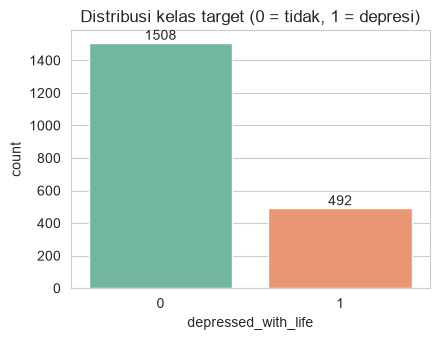

In [24]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x=TARGET, data=df, ax=ax, palette="Set2")
ax.set_title("Distribusi kelas target (0 = tidak, 1 = depresi)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/01_distribusi_target.png", dpi=150); plt.show()

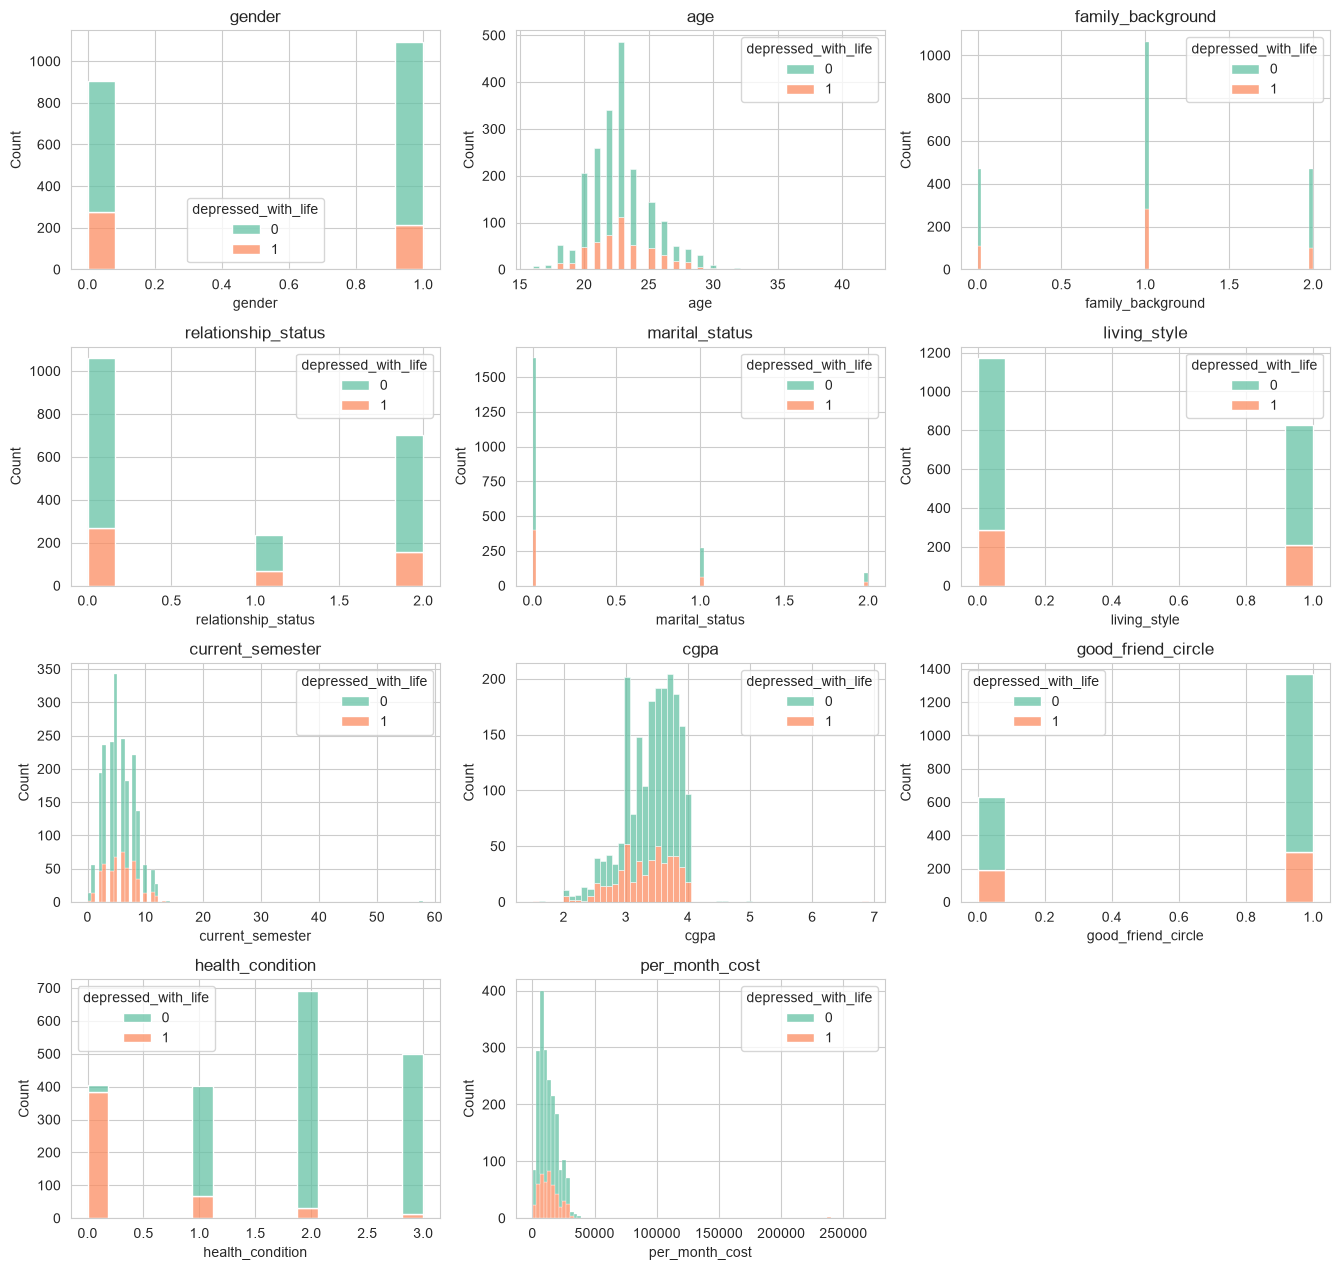

In [25]:
num_cols_eda = [c for c in df.select_dtypes(include=[np.number]).columns if c != TARGET]
if num_cols_eda:
    n = len(num_cols_eda); ncol = 3; nrow = int(np.ceil(n/ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.5*ncol, 3.2*nrow))
    axes = np.array(axes).reshape(-1)
    for ax, c in zip(axes, num_cols_eda):
        sns.histplot(data=df, x=c, hue=TARGET, kde=False, ax=ax, multiple="stack", palette="Set2")
        ax.set_title(c)
    for ax in axes[n:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/02_distribusi_numerik.png", dpi=150); plt.show()

In [29]:
cat_cols_eda = [c for c in df.select_dtypes(include=["object", "string"]).columns]
if cat_cols_eda:
    n = len(cat_cols_eda); ncol = 2; nrow = int(np.ceil(n/ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7*ncol, 3.6*nrow))
    axes = np.array(axes).reshape(-1)
    for ax, c in zip(axes, cat_cols_eda):
        ct = pd.crosstab(df[c], df[TARGET], normalize="index")*100
        ct.plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
        ax.set_title(f"% depresi per kategori: {c}"); ax.set_ylabel("%"); ax.legend(title=TARGET)
        ax.tick_params(axis="x", rotation=45)
    for ax in axes[n:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/03_kategori_vs_target.png", dpi=150); plt.show()

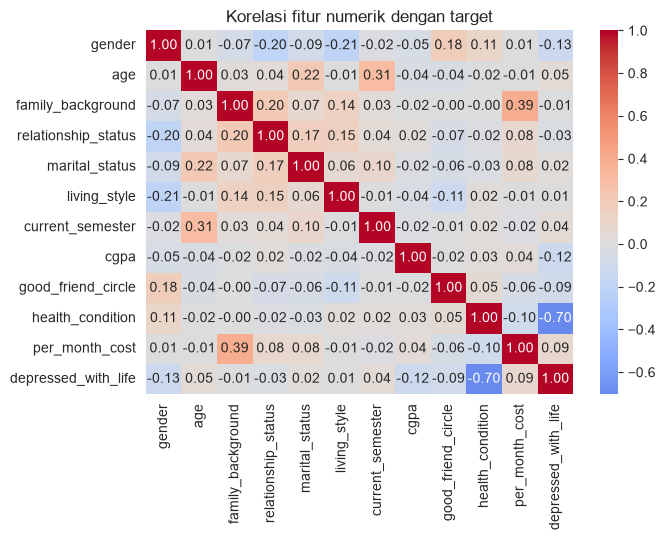

In [28]:
if len(num_cols_eda) >= 2:
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(df[num_cols_eda + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Korelasi fitur numerik dengan target")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/04_korelasi.png", dpi=150); plt.show()

## 5. Menentukan variabel dominan

Variabel dominan adalah kolom yang sangat kuat memprediksi target dan berpotensi "membocorkan" jawaban
(pada dataset ini umumnya kolom pertanyaan **pikiran bunuh diri**). Notebook mendeteksi kolom yang namanya
mengandung kata `suicid`. Jika tidak ada, variabel dominan ditentukan otomatis dari fitur terpenting
pada S2 (lihat bagian 7).

In [30]:
suicid_cols = [c for c in df.columns if "suicid" in c]
DOMINANT = suicid_cols[0] if suicid_cols else None
print("Variabel dominan terdeteksi:", DOMINANT)

Variabel dominan terdeteksi: None


## 4. Perancangan Metode Data Mining (Soal 4)

**a. Konsep dasar Decision Tree (CART).** Model berbentuk pohon yang membagi data secara berulang menjadi dua cabang berdasarkan fitur dan ambang yang paling memisahkan kelas, diukur dengan *Gini impurity* atau *entropy*. Hasilnya berupa aturan "jika-maka" yang transparan sehingga cocok untuk keputusan di bidang kesehatan. Kompleksitas dikendalikan dengan `max_depth`, `min_samples_leaf`, dan *cost-complexity pruning* (`ccp_alpha`).

**b. Tahapan penelitian:** pengumpulan data -> pembersihan dan preprocessing -> eksplorasi data (EDA) -> pembagian data -> pemodelan (tuning) -> evaluasi -> ekstraksi aturan keputusan -> validasi eksternal.

**c. Persiapan dataset.** Pembagian 80:20 (*stratified*): sekitar 1.600 data latih dan 400 data uji. Tuning memakai *Stratified 5-Fold CV* pada data latih saja. Ruang pencarian: `criterion` (gini, entropy), `max_depth` (3, 5, 7, 10), `min_samples_leaf` (1, 5, 10), `ccp_alpha` (0, 0.001, 0.005), dengan skor F1.

**d. Alasan dibanding alternatif.** Random Forest dan *neural network* umumnya lebih akurat tetapi sulit dijelaskan. KNN sensitif terhadap skala dan lambat pada data besar. Naive Bayes mengasumsikan fitur saling independen padahal fitur survei saling berkaitan. Decision Tree dipilih karena **interpretabilitasnya**. Perbandingan antar-algoritma tidak dilakukan karena penelitian memakai satu algoritma.

## 6. Pembagian data dan pipeline preprocessing

In [31]:
def make_preprocessor(X):
    num = X.select_dtypes(include=[np.number]).columns.tolist()
    cat = [c for c in X.columns if c not in num]
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    return pre

def split_data(frame, drop_cols=()):
    X = frame.drop(columns=[TARGET] + list(drop_cols))
    y = frame[TARGET]
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = split_data(df)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi kelas latih:", y_train.mean().round(3), "| uji:", y_test.mean().round(3))

Data latih: (1600, 11) | Data uji: (400, 11)
Proporsi kelas latih: 0.246 | uji: 0.245


## 5. Rancangan Eksperimen dan Evaluasi (Soal 5)

**a. Skenario eksperimen**
| Skenario | Deskripsi |
|---|---|
| S1 | Decision Tree default, semua fitur (baseline) |
| S2 | Tuning + pruning, semua fitur |
| S3 | Tuning + pruning, **tanpa variabel dominan** |
| S4 | Tuning, `class_weight='balanced'`, semua fitur |

**b. Metrik evaluasi.** Accuracy, Precision, Recall, F1-score, ROC-AUC, dan *confusion matrix*. F1 dan Recall kelas depresi ditekankan karena kegagalan mendeteksi mahasiswa yang berisiko lebih merugikan daripada alarm palsu.

**c. Menjawab rumusan masalah.**
- Kinerja S1/S2 -> rumusan masalah 1.
- Selisih S2 vs S3 -> rumusan masalah 2.
- *Feature importance* dan aturan pohon -> rumusan masalah 3.
- Recall S4 vs S2 -> rumusan masalah 4.

**d. Keberhasilan penelitian** diukur dari: (i) kinerja di atas baseline kelas mayoritas, (ii) selisih antar-fold CV yang kecil (std rendah), (iii) selisih akurasi latih-uji yang kecil setelah pruning, dan (iv) hasil pada data validasi eksternal yang konsisten dengan data uji.

**e. Perbandingan konfigurasi.** Dibandingkan konfigurasi `criterion`, kedalaman pohon, dan pruning (tanpa algoritma lain).

## 7. Pemodelan dan evaluasi

Fungsi bantu untuk melatih, mengevaluasi, dan mencatat hasil setiap skenario.
Semua tuning memakai *Stratified 5-Fold CV* pada data latih saja (tanpa menyentuh data uji).

In [32]:
results = []          # tabel ringkasan
models = {}           # model per skenario
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, model, Xtr, Xte, ytr, yte, note=""):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    row = {
        "Skenario": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(yte, proba),
        "Catatan": note,
    }
    results.append(row); models[name] = (model, Xte, yte)
    print(f"=== {name} ===")
    print(classification_report(yte, pred, target_names=["Tidak depresi", "Depresi"], zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["Tidak", "Depresi"]).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}"); plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/cm_{name.split()[0]}.png", dpi=150); plt.show()

def tuned_tree(Xtr, ytr, class_weight=None):
    pipe = Pipeline([("pre", make_preprocessor(Xtr)),
                     ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight=class_weight))])
    grid = {
        "clf__criterion": ["gini", "entropy"],
        "clf__max_depth": [3, 5, 7, 10],
        "clf__min_samples_leaf": [1, 5, 10],
        "clf__ccp_alpha": [0.0, 0.001, 0.005],
    }
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=skf, n_jobs=-1, refit=True)
    gs.fit(Xtr, ytr)
    return gs

### S1 - Decision Tree default (semua fitur)

=== S1 Default (semua fitur) ===
               precision    recall  f1-score   support

Tidak depresi       0.96      0.96      0.96       302
      Depresi       0.89      0.88      0.88        98

     accuracy                           0.94       400
    macro avg       0.92      0.92      0.92       400
 weighted avg       0.94      0.94      0.94       400



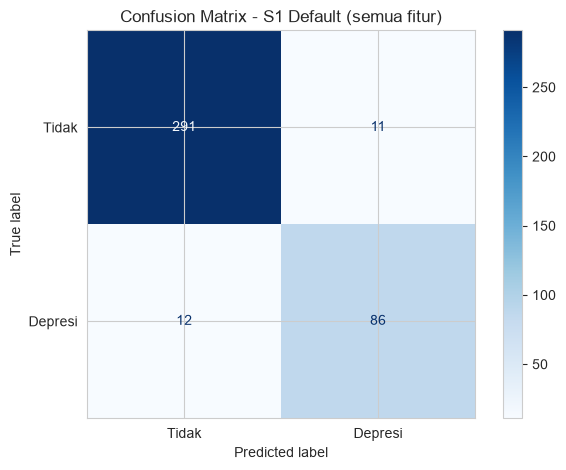

In [33]:
s1 = Pipeline([("pre", make_preprocessor(X_train)),
               ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))])
s1.fit(X_train, y_train)
evaluate("S1 Default (semua fitur)", s1, X_train, X_test, y_train, y_test,
         note=f"kedalaman={s1.named_steps['clf'].get_depth()}")

### S2 - Tuning dan pruning (semua fitur)

Parameter terbaik S2: {'clf__ccp_alpha': 0.005, 'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 1}
F1 CV terbaik: 0.9125
=== S2 Tuning+Pruning (semua fitur) ===
               precision    recall  f1-score   support

Tidak depresi       0.98      0.99      0.99       302
      Depresi       0.96      0.95      0.95        98

     accuracy                           0.98       400
    macro avg       0.97      0.97      0.97       400
 weighted avg       0.98      0.98      0.98       400



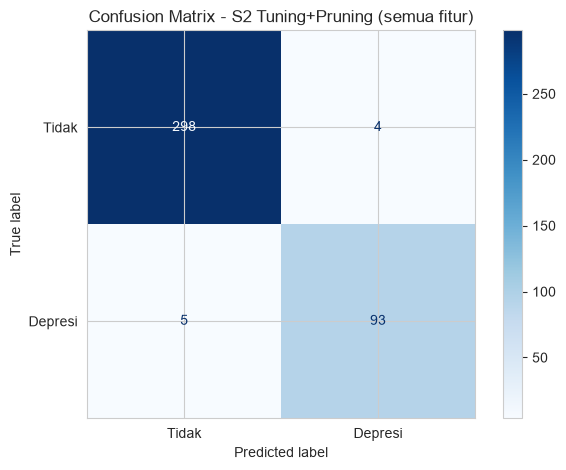

In [34]:
gs2 = tuned_tree(X_train, y_train)
print("Parameter terbaik S2:", gs2.best_params_)
print("F1 CV terbaik:", round(gs2.best_score_, 4))
s2 = gs2.best_estimator_
evaluate("S2 Tuning+Pruning (semua fitur)", s2, X_train, X_test, y_train, y_test,
         note=str(gs2.best_params_))

### S3 - Tuning dan pruning, tanpa variabel dominan

Variabel dominan ditentukan otomatis dari fitur terpenting S2: health_condition
Variabel dominan yang dibuang: health_condition
Parameter terbaik S3: {'clf__ccp_alpha': 0.0, 'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_leaf': 1} | F1 CV: 0.3523
=== S3 Tanpa variabel dominan ===
               precision    recall  f1-score   support

Tidak depresi       0.80      0.84      0.82       302
      Depresi       0.41      0.35      0.38        98

     accuracy                           0.72       400
    macro avg       0.60      0.59      0.60       400
 weighted avg       0.70      0.72      0.71       400



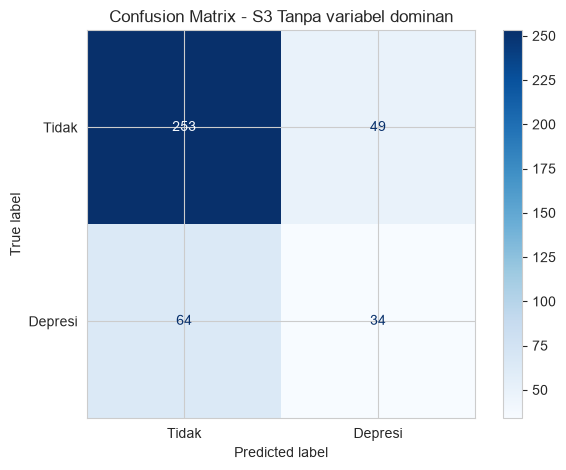

In [35]:
# Jika variabel dominan tidak terdeteksi lewat nama kolom, pakai fitur terpenting dari S2
if DOMINANT is None:
    names = s2.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(s2.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    top_feat = imp.index[0]
    DOMINANT = next((c for c in X_train.columns if c in top_feat), None)
    print("Variabel dominan ditentukan otomatis dari fitur terpenting S2:", DOMINANT)

assert DOMINANT in df.columns, "Variabel dominan tidak ditemukan"
X_train3, X_test3, y_train3, y_test3 = split_data(df, drop_cols=[DOMINANT])
gs3 = tuned_tree(X_train3, y_train3)
print("Variabel dominan yang dibuang:", DOMINANT)
print("Parameter terbaik S3:", gs3.best_params_, "| F1 CV:", round(gs3.best_score_, 4))
s3 = gs3.best_estimator_
evaluate("S3 Tanpa variabel dominan", s3, X_train3, X_test3, y_train3, y_test3,
         note=f"dibuang: {DOMINANT}")

### S4 - Tuning dengan `class_weight='balanced'` (semua fitur)

Parameter terbaik S4: {'clf__ccp_alpha': 0.0, 'clf__criterion': 'entropy', 'clf__max_depth': 7, 'clf__min_samples_leaf': 10} | F1 CV: 0.8765
=== S4 Class weight balanced ===
               precision    recall  f1-score   support

Tidak depresi       0.98      0.94      0.96       302
      Depresi       0.84      0.95      0.89        98

     accuracy                           0.94       400
    macro avg       0.91      0.94      0.93       400
 weighted avg       0.95      0.94      0.94       400



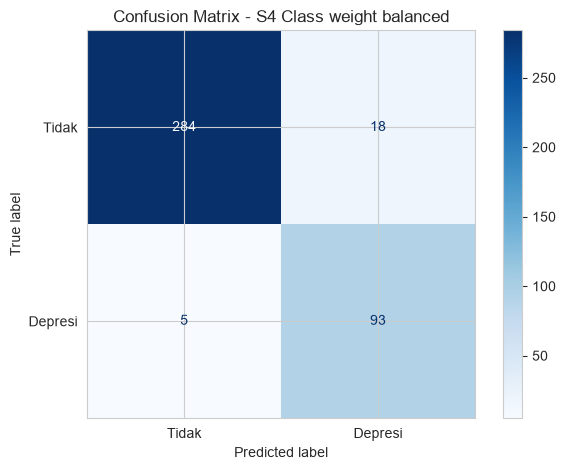

In [36]:
gs4 = tuned_tree(X_train, y_train, class_weight="balanced")
print("Parameter terbaik S4:", gs4.best_params_, "| F1 CV:", round(gs4.best_score_, 4))
s4 = gs4.best_estimator_
evaluate("S4 Class weight balanced", s4, X_train, X_test, y_train, y_test,
         note=str(gs4.best_params_))

## 8. Perbandingan skenario

,Skenario,Accuracy,Precision,Recall,F1,ROC-AUC
0,S1 Default (semua fitur),0.9425,0.8866,0.8776,0.8821,0.9206
1,S2 Tuning+Pruning (semua fitur),0.9775,0.9588,0.9490,0.9538,0.9688
2,S3 Tanpa variabel dominan,0.7175,0.4096,0.3469,0.3757,0.5949
3,S4 Class weight balanced,0.9425,0.8378,0.9490,0.8900,0.9619


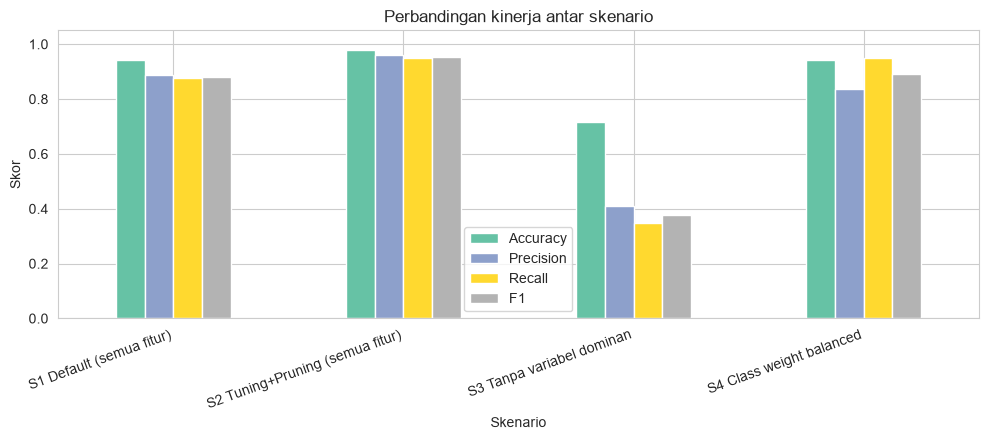

In [37]:
res = pd.DataFrame(results)
num_cols_res = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
res[num_cols_res] = res[num_cols_res].round(4)
display(res.drop(columns=["Catatan"]))
res.to_csv(f"{OUTPUT_DIR}/hasil_perbandingan_skenario.csv", index=False)

ax = res.set_index("Skenario")[["Accuracy", "Precision", "Recall", "F1"]].plot(
        kind="bar", figsize=(10, 4.5), colormap="Set2")
ax.set_ylim(0, 1.05); ax.set_title("Perbandingan kinerja antar skenario"); ax.set_ylabel("Skor")
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_perbandingan_skenario.png", dpi=150); plt.show()

In [38]:
# Stabilitas model: cross-validation pada data latih (mean ± std)
rows = []
for name, mdl, Xtr_, ytr_ in [("S1", s1, X_train, y_train), ("S2", s2, X_train, y_train),
                              ("S3", s3, X_train3, y_train3), ("S4", s4, X_train, y_train)]:
    cv = cross_validate(mdl, Xtr_, ytr_, cv=skf, scoring=["accuracy", "f1"], n_jobs=-1)
    rows.append({"Skenario": name,
                 "Accuracy (mean)": cv["test_accuracy"].mean(), "Accuracy (std)": cv["test_accuracy"].std(),
                 "F1 (mean)": cv["test_f1"].mean(), "F1 (std)": cv["test_f1"].std()})
cv_table = pd.DataFrame(rows).round(4)
display(cv_table)
cv_table.to_csv(f"{OUTPUT_DIR}/hasil_cross_validation.csv", index=False)

,Skenario,Accuracy (mean),Accuracy (std),F1 (mean),F1 (std)
0,S1,0.9244,0.0121,0.8476,0.0221
1,S2,0.9569,0.0091,0.9125,0.0187
2,S3,0.7169,0.0135,0.3523,0.0229
3,S4,0.9362,0.0083,0.8765,0.0158


## 9. Validasi eksternal (opsional)

Model terbaik diuji pada **sisa data di luar sampel 2.000** untuk melihat apakah hasilnya tetap konsisten.

In [39]:
if df_rest is not None and len(df_rest) > 0:
    Xr = df_rest.drop(columns=[TARGET]); yr = df_rest[TARGET]
    ext = []
    for name, mdl, drop in [("S2", s2, []), ("S3", s3, [DOMINANT]), ("S4", s4, [])]:
        Xe = Xr.drop(columns=drop)
        p = mdl.predict(Xe)
        ext.append({"Skenario": name, "Jumlah data": len(Xe),
                    "Accuracy": accuracy_score(yr, p), "Recall": recall_score(yr, p),
                    "F1": f1_score(yr, p)})
    ext_table = pd.DataFrame(ext).round(4)
    display(ext_table)
    ext_table.to_csv(f"{OUTPUT_DIR}/hasil_validasi_eksternal.csv", index=False)
else:
    print("Tidak ada data sisa (USE_SAMPLE=False atau data <= N_SAMPLE).")

,Skenario,Jumlah data,Accuracy,Recall,F1
0,S2,799,0.9662,0.8832,0.9280
1,S3,799,0.6934,0.3299,0.3467
2,S4,799,0.9274,0.9137,0.8612


## 10. Feature importance dan aturan keputusan

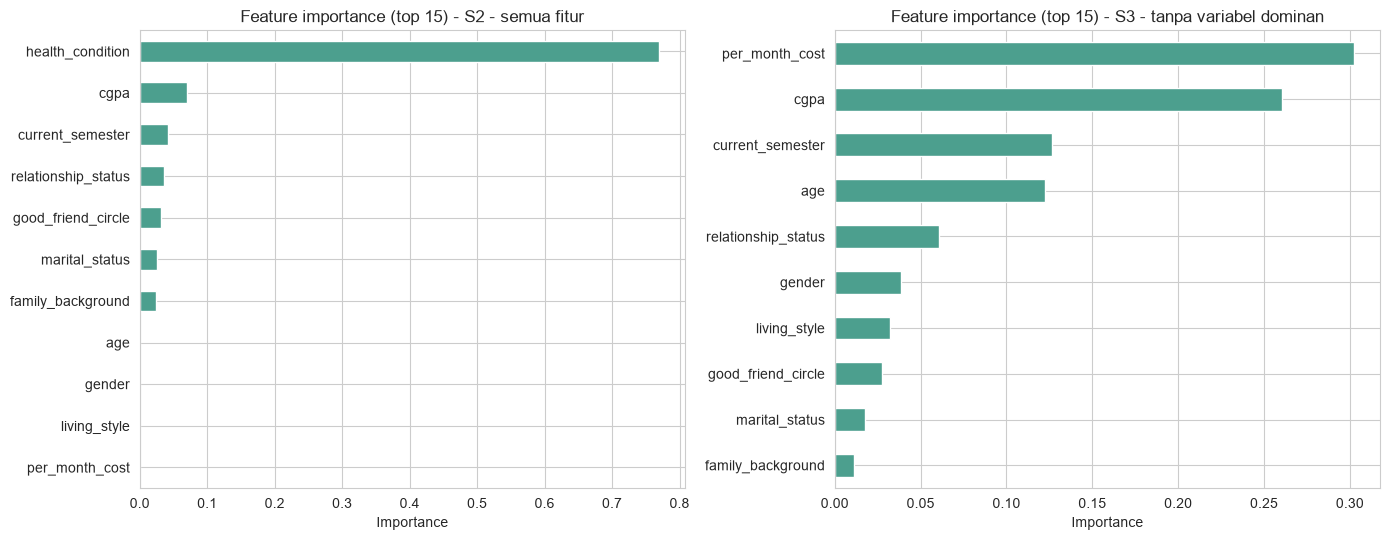

,S2 importance
health_condition,0.7696
cgpa,0.0705
current_semester,0.0416
relationship_status,0.0367
good_friend_circle,0.0314
marital_status,0.0261
family_background,0.0241
age,0.0000
gender,0.0000
living_style,0.0000


,S3 importance
per_month_cost,0.3024
cgpa,0.2605
current_semester,0.1267
age,0.1226
relationship_status,0.0608
gender,0.0385
living_style,0.0322
good_friend_circle,0.0276
marital_status,0.0175
family_background,0.0114


In [40]:
def top_importance(model, k=15):
    names = model.named_steps["pre"].get_feature_names_out()
    names = [n.split("__", 1)[-1] for n in names]
    s = pd.Series(model.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    return s.head(k)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, mdl) in zip(axes, [("S2 - semua fitur", s2), ("S3 - tanpa variabel dominan", s3)]):
    imp = top_importance(mdl)
    imp[::-1].plot(kind="barh", ax=ax, color="#4c9f8e")
    ax.set_title(f"Feature importance (top 15) - {title}"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/06_feature_importance.png", dpi=150); plt.show()
display(top_importance(s2, 10).round(4).to_frame("S2 importance"))
display(top_importance(s3, 10).round(4).to_frame("S3 importance"))

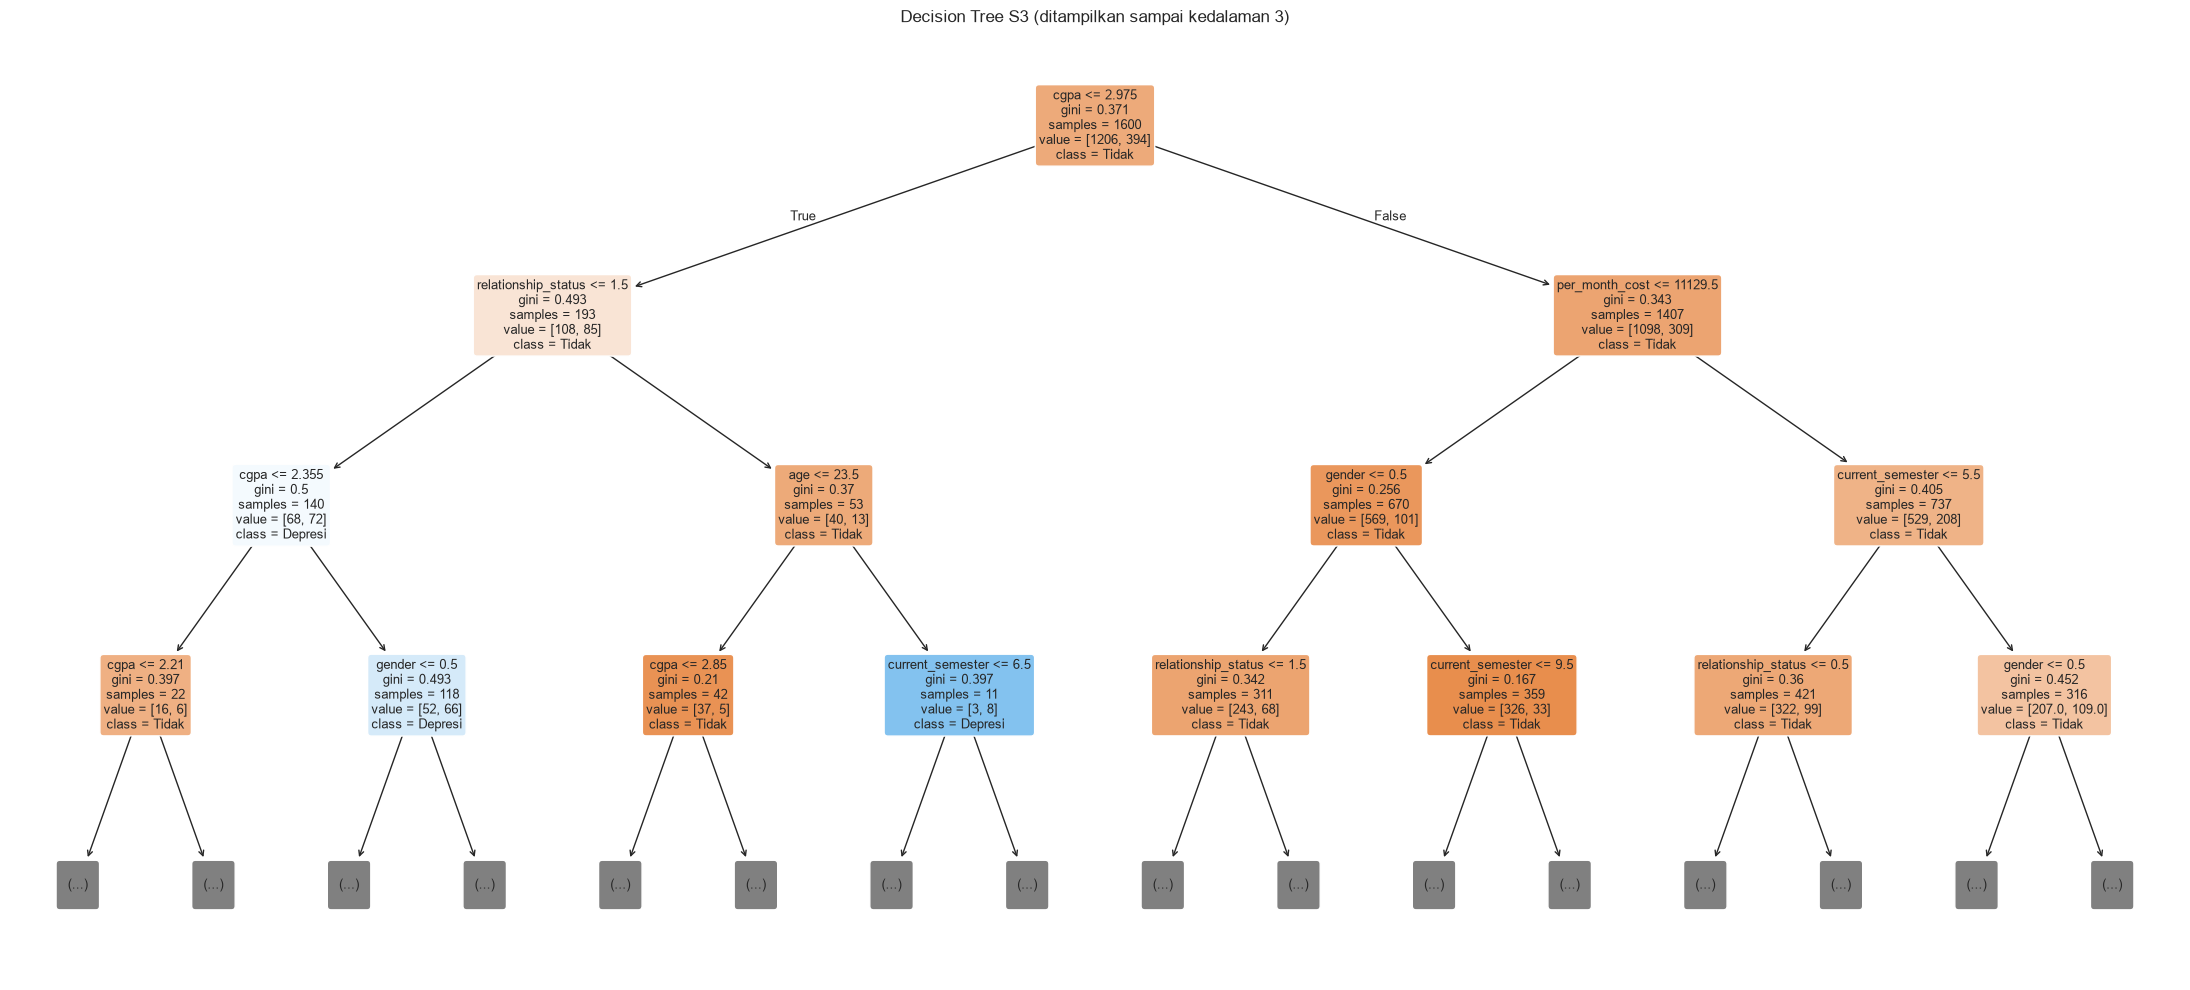

In [41]:
# Visualisasi pohon S3 (dipotong sampai kedalaman 3 agar terbaca)
feat3 = [n.split("__", 1)[-1] for n in s3.named_steps["pre"].get_feature_names_out()]
plt.figure(figsize=(22, 10))
plot_tree(s3.named_steps["clf"], feature_names=feat3, class_names=["Tidak", "Depresi"],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Decision Tree S3 (ditampilkan sampai kedalaman 3)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/07_pohon_S3.png", dpi=150); plt.show()

In [42]:
# Aturan keputusan (teks) - S3, tanpa variabel dominan
rules_s3 = export_text(s3.named_steps["clf"], feature_names=feat3, max_depth=4)
print(rules_s3)
with open(f"{OUTPUT_DIR}/aturan_keputusan_S3.txt", "w", encoding="utf-8") as f:
    f.write(rules_s3)

# Aturan keputusan - S2
feat2 = [n.split("__", 1)[-1] for n in s2.named_steps["pre"].get_feature_names_out()]
rules_s2 = export_text(s2.named_steps["clf"], feature_names=feat2, max_depth=4)
with open(f"{OUTPUT_DIR}/aturan_keputusan_S2.txt", "w", encoding="utf-8") as f:
    f.write(rules_s2)

|--- cgpa <= 2.98
|   |--- relationship_status <= 1.50
|   |   |--- cgpa <= 2.35
|   |   |   |--- cgpa <= 2.21
|   |   |   |   |--- per_month_cost <= 14000.00
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |--- per_month_cost >  14000.00
|   |   |   |   |   |--- class: 0
|   |   |   |--- cgpa >  2.21
|   |   |   |   |--- class: 0
|   |   |--- cgpa >  2.35
|   |   |   |--- gender <= 0.50
|   |   |   |   |--- per_month_cost <= 9754.00
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- per_month_cost >  9754.00
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- gender >  0.50
|   |   |   |   |--- per_month_cost <= 5250.00
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- per_month_cost >  5250.00
|   |   |   |   |   |--- truncated branch of depth 6
|   |--- relationship_status >  1.50
|   |   |--- age <= 23.50
|   |   |   |--- cgpa <= 2.85
|   |   |   |   |--- per_month_cost <= 28201.00
|   |   |   |  

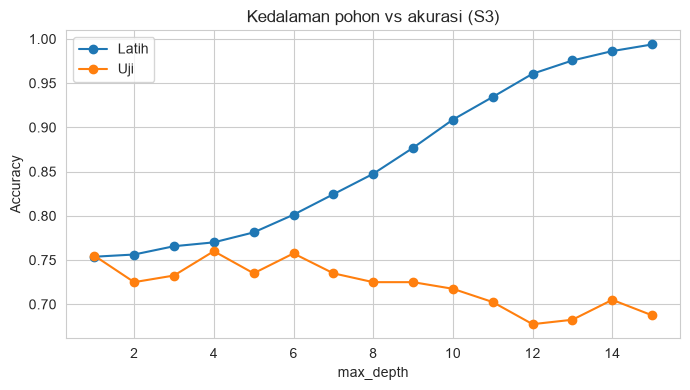

In [43]:
# Kurva kedalaman pohon vs kinerja (S3): menunjukkan efek pruning/kedalaman
depths = range(1, 16)
tr_acc, te_acc = [], []
Xtr_t = s3.named_steps["pre"].transform(X_train3); Xte_t = s3.named_steps["pre"].transform(X_test3)
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xtr_t, y_train3)
    tr_acc.append(t.score(Xtr_t, y_train3)); te_acc.append(t.score(Xte_t, y_test3))
plt.figure(figsize=(7, 4))
plt.plot(depths, tr_acc, marker="o", label="Latih"); plt.plot(depths, te_acc, marker="o", label="Uji")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Kedalaman pohon vs akurasi (S3)")
plt.legend(); plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/08_depth_curve.png", dpi=150); plt.show()

## 5.1 Ringkasan hasil dan interpretasi
Sel di bawah menyusun kesimpulan otomatis dari angka hasil eksperimenmu. **Salin hasilnya ke bagian "Hasil dan Pembahasan" laporan, lalu tambahkan interpretasimu sendiri.**

**Batasan penelitian**
- Data berasal dari survei *self-report*, bukan diagnosis klinis.
- Sampel 2.000 data dapat memberi hasil sedikit berbeda dari data penuh (lihat validasi eksternal).
- Hasil tidak boleh dipakai sebagai alat diagnosis; keputusan klinis tetap oleh tenaga profesional.

In [44]:
# ===== KESIMPULAN OTOMATIS (terisi dari hasil run-mu) =====
r = res.set_index("Skenario")
def get(prefix, col):
    key = [k for k in r.index if k.startswith(prefix)][0]
    return r.loc[key, col]

acc1, acc2, acc3 = get("S1","Accuracy"), get("S2","Accuracy"), get("S3","Accuracy")
f11, f12, f13, f14 = get("S1","F1"), get("S2","F1"), get("S3","F1"), get("S4","F1")
rc2, rc4 = get("S2","Recall"), get("S4","Recall")

# selisih latih-uji (indikasi overfitting)
gap1 = s1.score(X_train, y_train) - s1.score(X_test, y_test)
gap2 = s2.score(X_train, y_train) - s2.score(X_test, y_test)

top3_s3 = ", ".join(top_importance(s3, 3).index.tolist())
top3_s2 = ", ".join(top_importance(s2, 3).index.tolist())

lines = []
lines.append(f"1) Kinerja Decision Tree: baseline S1 mencapai akurasi {acc1:.3f} (F1 {f11:.3f}). "
              f"Setelah tuning dan pruning (S2) akurasi menjadi {acc2:.3f} (F1 {f12:.3f}). "
              f"Selisih akurasi latih-uji turun dari {gap1:.3f} (S1) menjadi {gap2:.3f} (S2), "
              + ("menandakan pruning mengurangi overfitting." if gap2 < gap1 else "sehingga pruning belum mengurangi overfitting secara jelas."))
drop = acc2 - acc3
lines.append(f"2) Pengaruh variabel dominan ('{DOMINANT}'): tanpa variabel ini (S3) akurasi {acc3:.3f} dan F1 {f13:.3f}; "
              f"terjadi perubahan akurasi sebesar {-drop:+.3f} dibanding S2. "
              + ("Penurunannya besar, artinya model sangat bergantung pada variabel tersebut." if drop > 0.05
                 else "Penurunannya kecil, artinya faktor lain sudah cukup informatif."))
lines.append(f"3) Fitur terpenting: S2 -> {top3_s2}; S3 (tanpa variabel dominan) -> {top3_s3}. "
              "Lihat aturan keputusan pada outputs/aturan_keputusan_S3.txt.")
lines.append(f"4) Penanganan kelas: recall kelas depresi S2 = {rc2:.3f} vs S4 (class_weight balanced) = {rc4:.3f}; "
              f"F1 S4 = {f14:.3f}. "
              + ("S4 meningkatkan recall." if rc4 > rc2 else "S4 tidak meningkatkan recall secara berarti."))
summary_text = "\n\n".join(lines)
print(summary_text)
with open(f"{OUTPUT_DIR}/kesimpulan_otomatis.txt", "w", encoding="utf-8") as f:
    f.write(summary_text)

1) Kinerja Decision Tree: baseline S1 mencapai akurasi 0.943 (F1 0.882). Setelah tuning dan pruning (S2) akurasi menjadi 0.978 (F1 0.954). Selisih akurasi latih-uji turun dari 0.057 (S1) menjadi -0.008 (S2), menandakan pruning mengurangi overfitting.

2) Pengaruh variabel dominan ('health_condition'): tanpa variabel ini (S3) akurasi 0.718 dan F1 0.376; terjadi perubahan akurasi sebesar -0.260 dibanding S2. Penurunannya besar, artinya model sangat bergantung pada variabel tersebut.

3) Fitur terpenting: S2 -> health_condition, cgpa, current_semester; S3 (tanpa variabel dominan) -> per_month_cost, cgpa, current_semester. Lihat aturan keputusan pada outputs/aturan_keputusan_S3.txt.

4) Penanganan kelas: recall kelas depresi S2 = 0.949 vs S4 (class_weight balanced) = 0.949; F1 S4 = 0.890. S4 tidak meningkatkan recall secara berarti.


---
# BAGIAN III - PENUTUP

## 6. Rencana Pelaksanaan Penelitian (Soal 6)

**a. Target capaian / luaran**
- Model Decision Tree (CART) terbaik untuk klasifikasi depresi mahasiswa
- Laporan perbandingan 4 skenario eksperimen
- Daftar aturan keputusan yang mudah dibaca
- Notebook Python yang dapat direproduksi (file ini)

**b. Jadwal kegiatan (6 minggu)**
| Minggu | Kegiatan |
|---|---|
| 1 | Studi literatur, unduh dataset, penyusunan proposal |
| 2 | Pembersihan data dan EDA |
| 3 | Pemodelan baseline dan tuning |
| 4 | Eksperimen skenario S1-S4 |
| 5 | Evaluasi, ekstraksi aturan, validasi eksternal |
| 6 | Penyusunan laporan dan presentasi |

**c. Pembagian tugas anggota kelompok** *(sesuaikan; hapus jika individu)*
| Anggota | Tugas |
|---|---|
| Anggota 1 | Studi literatur, penulisan laporan |
| Anggota 2 | Preprocessing dan EDA |
| Anggota 3 | Pemodelan, evaluasi, dan interpretasi aturan |

**d. Rencana implementasi / pemanfaatan.** Aturan keputusan dapat dijadikan bahan rekomendasi bagi layanan konseling kampus untuk skrining awal, atau dasar dashboard sederhana (misalnya Streamlit). Model tidak dipakai untuk mendiagnosis individu.

## Daftar Pustaka
*(Lengkapi nama penulis, tahun, volume, dan halaman dari halaman depan PDF masing-masing; pastikan tahun masuk rentang 5 tahun terakhir; sesuaikan gaya sitasi dengan ketentuan dosen.)*

[1] Jurnal CoreIT, UIN Sultan Syarif Kasim Riau (2025). Prediksi depresi mahasiswa dengan Particle Swarm Optimization dan Random Forest. https://ejournal.uin-suska.ac.id/index.php/coreit/article/download/35954/pdf

[2] Setiawan, Yasin & Desianti. Analisis depresi mahasiswa dengan Random Forest, Decision Tree, Naive Bayes, dan KNN. *IKOMTI*. https://ejournal.uhb.ac.id/index.php/IKOMTI/article/download/1756/965/10110

[3] Prosiding 55 JAIIO (2026). Deteksi depresi mahasiswa dengan metodologi KDD. https://55jaiio.sadio.org.ar/wp-content/uploads/2026/07/115.pdf

[4] Jayadi dkk. Deteksi Dini Kesehatan Mental Mahasiswa dengan Machine Learning: Perbandingan Algoritma Decision Tree dan Random Forest. https://ojs.uniska-bjm.ac.id/index.php/JIT/article/download/21251/8268/56903

[5] Anggreani, Danuputri dkk. Classification of Student Mental Health Based on Academic and Social Variables Using the Decision Tree Method. https://journal.ubm.ac.id/index.php/alu/article/download/8652/3254

[6] hopesb. *Student Depression Dataset*. Kaggle. https://www.kaggle.com/datasets/hopesb/student-depression-dataset

In [45]:
print("Semua keluaran tersimpan di folder:", os.path.abspath(OUTPUT_DIR))
print(sorted(os.listdir(OUTPUT_DIR)))

Semua keluaran tersimpan di folder: d:\PenembanganData\outputs
['.gitkeep', '01_distribusi_target.png', '02_distribusi_numerik.png', '04_korelasi.png', '05_perbandingan_skenario.png', '06_feature_importance.png', '07_pohon_S3.png', '08_depth_curve.png', 'aturan_keputusan_S2.txt', 'aturan_keputusan_S3.txt', 'cm_S1.png', 'cm_S2.png', 'cm_S3.png', 'cm_S4.png', 'hasil_cross_validation.csv', 'hasil_perbandingan_skenario.csv', 'hasil_validasi_eksternal.csv', 'kesimpulan_otomatis.txt']
